# Starrydata thermoelectric audit: material families, Seebeck–carrier matching, n/p coverage

**What this notebook does.** It audits the public Starrydata2 *ThermoelectricMaterials* snapshot for how much Seebeck-coefficient data can be paired with carrier-concentration or Hall-coefficient data on the **same sample**, broken down by material family and carrier type. It does not fit models or make physical claims.

**Status of every count below: _candidate usable data_.** These records passed automated screens only. Before any record is used as experimental evidence it has to be checked against the source paper.

Source: Starrydata2 open dataset (CC BY 4.0), ThermoelectricMaterials project split from the daily release mirror of the official dump. Katsura *et al.*, “Starrydata: from published plots to shared materials data”, *Sci. Technol. Adv. Mater.: Methods* **5**, 2506976 (2025), https://doi.org/10.1080/27660400.2025.2506976. The snapshot date and file hashes are in `out/run_manifest.json`.

## 0. Definitions (used consistently in every table)

| Term | Definition |
|---|---|
| **sample** | One Starrydata sample record, identified by the pair **(SID, sample_id)**. SID identifies the paper. All joins use both keys, even though `sample_id` happens to be globally unique in this snapshot (checked in §1). |
| **curve** | One digitized plot series (a row of `curves.csv`) with x/y arrays and axis names and units. |
| **point** | One digitized (x, y) pair from a curve. Points are **not** independent specimens. A 50-point S(T) curve is one specimen measured at 50 temperatures, and digitization adds reading error. |
| **valid Seebeck point with temperature** | Seebeck-type property (name variants in §2) with an SI unit of dimension V/K and a recognized temperature axis. After conversion, 0 < T ≤ 2000 K and \|S\| ≤ 50 mV/K. Excludes exact duplicates and curves where a curator note flags a unit or axis problem. |
| **carrier/Hall data** | Carrier concentration (dimension m⁻³) or Hall coefficient (m³/C). The property name records *what was plotted*, not *how it was measured*. “Carrier concentration” is **not** assumed to be a Hall measurement. |
| **temperature-matched candidate point** | A valid Seebeck point that has at least one valid carrier or Hall point on the **same (SID, sample_id)** with \|ΔT\| ≤ tolerance. Only measured points are paired; there is **no interpolation or extrapolation**. The nearest partner is kept separately for each carrier quantity. |
| **matched carrier points used** | The number of distinct carrier/Hall points consumed by matching. This is the conservative “independent pairs” count, because dense S(T) curves reuse one carrier point several times. |
| **ambiguous match** | More than one carrier curve of the same quantity offers a partner within tolerance, and their values differ (for example two specimens or runs, or heating vs cooling). |
| **direct S-vs-n curve** | Seebeck plotted directly against carrier concentration (Pisarenko-type plot). Temperature is **not** in the axes, and each point may be a different specimen. These are counted separately, and the temperature has to be recovered from the paper. |
| **usable** | Shorthand for *candidate usable after automated screening*. It never means verified. |


In [1]:
import os, json, sys, subprocess
import numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
import starry_te_audit as A
cfg = A.Config()
print("module version", A.__version__); print(json.dumps(cfg.to_dict(), indent=1))

module version 1.0.0
{
 "major_frac": 0.1,
 "dopant_frac": 0.02,
 "partner_frac": 0.1,
 "system_core_min": 0.9,
 "t_min_K": 0.0,
 "t_max_K": 2000.0,
 "seebeck_abs_max": 0.05,
 "carrier_abs_min": 1e+18,
 "carrier_abs_max": 1e+30,
 "hall_abs_min": 1e-13,
 "hall_abs_max": 100.0,
 "axis_valid_share": 0.9,
 "axis_check_min_K": 1.0,
 "tolerances_K": [
  0.0,
  1.0,
  5.0,
  10.0
 ],
 "default_tol_K": 5.0,
 "exact_eps_K": 1e-06,
 "dup_round_sig": 10,
 "use_signed_concentration_as_type": false
}


### 0.1 Validation of the matching, unit and classification code on small synthetic examples
The tests cover these cases:
- a `sample_id` repeated across two papers (must not be joined);
- SI unit-dimension equivalence and a volts-not-V/K mismatch;
- conversions of 1/T, 1000/T and °C axes, and refusal of an implausibly scaled axis;
- no interpolation when the partner temperature falls between S points;
- the 0/1/5/10 K tolerances and missing temperatures;
- carrier reuse, ambiguity and exact duplicates;
- carrier types: positive n only → unknown, Hall sign, a Hall sign change, text naming both n and p, a text-vs-Hall conflict, and an S sign that is never used for typing;
- composition parsing: dopants, grouped formulas, symbolic, composite, percent and non-formula strings;
- chemical groups, candidate systems, label contradictions and missing-label states.

In [2]:
r = subprocess.run([sys.executable, "-m", "unittest", "-v", "test_starry_te_audit"], capture_output=True, text=True)
print(r.stderr[-3500:])

test_seebeck_disagreement_is_flagged_not_reassigned (test_starry_te_audit.TestCarrierType.test_seebeck_disagreement_is_flagged_not_reassigned) ... ok
test_text_patterns (test_starry_te_audit.TestCarrierType.test_text_patterns) ... ok
test_types (test_starry_te_audit.TestCarrierType.test_types) ... ok
test_groups_and_systems (test_starry_te_audit.TestComposition.test_groups_and_systems) ... ok
test_label_checks_and_missing_states (test_starry_te_audit.TestComposition.test_label_checks_and_missing_states) ... ok
test_parse (test_starry_te_audit.TestComposition.test_parse) ... ok
test_repeated_sample_id_across_papers_is_not_joined (test_starry_te_audit.TestJoinKeys.test_repeated_sample_id_across_papers_is_not_joined) ... ok
test_direct_S_vs_n_curve_is_separate (test_starry_te_audit.TestTemperatureMatching.test_direct_S_vs_n_curve_is_separate) ... ok
test_exact_duplicate_observation (test_starry_te_audit.TestTemperatureMatching.test_exact_duplicate_observation) ... ok
test_exact_zero_toler

## 1. Run the pipeline and check key integrity
`run_audit.py` loads the three CSVs, parses `sample_info`, parses and classifies compositions, explodes the target curves into points, assigns carrier types, runs matching at every tolerance, and writes all CSVs and the manifest.

In [3]:
r = subprocess.run([sys.executable, "run_audit.py", "raw_user", "out"], capture_output=True, text=True); print(r.stdout, r.stderr[-2000:])
st = pd.read_pickle("out/_state.pkl")
S, P, audit, M = st["S"], st["P"], st["audit"], st["matches"]
man = json.load(open("out/run_manifest.json"))
print("snapshot:", man["upstream_db_snapshot"])
for k, v in man["inputs"].items(): print(k, v["sha256"][:16], "gz bytes identical to upstream:", v["hash_matches_upstream"], "| decompressed content sha256:", v["content_sha256"][:16])
pd.Series(st["integrity"], name="value").to_frame()

built 51.6 s
done 64.2 s
 
snapshot: 2026-09-23 02:00:01 UTC+0900 (JST)
ThermoelectricMaterials_samples.csv.gz b70de7a34bfdb417 gz bytes identical to upstream: False | decompressed content sha256: 384cabd4b2b1b7b0
ThermoelectricMaterials_curves.csv.gz 6dd51f3bffa842b1 gz bytes identical to upstream: False | decompressed content sha256: 509be0c7466ca091
ThermoelectricMaterials_papers.csv.gz 6449d33242a1bb1a gz bytes identical to upstream: False | decompressed content sha256: 664b15a7f371f11c


,value
samples_rows,55481
curves_rows,156992
papers_rows,9522
samples_missing_SID,0
samples_missing_sample_id,0
curves_missing_SID,0
curves_missing_sample_id,0
"samples_duplicate_(SID,sample_id)",0
sample_id_values_repeated_across_SIDs,0
curve_keys_without_sample_record,0


**Reading.** There are no missing SID or sample_id keys and no duplicate (SID, sample_id) records. In this snapshot, no `sample_id` value is shared by two SIDs. The joins still use both keys, and the synthetic test shows this protects against repeated IDs if they appear in future snapshots. Every curve key has a sample record. Three curve SIDs have no row in the project's papers file; their DOIs are still present on the sample records.

## 2. Measurement identification, units and axis definitions

**Property-name variants accepted** (the others found by the scan are listed with their reason for exclusion):

| quantity | included names | excluded (reason) |
|---|---|---|
| Seebeck | Seebeck coefficient, thermopower, Thermopower, Thermoelectric power, S, “Seebeck  coefficient”, zero-B thermopower | Calculated Seebeck coefficient (calculated, not measured); “Seebeck coefficient at 550 K” plotted vs T (name contradicts the axis) |
| carrier concentration | Carrier concentration, Carrier Density n, hall density, Hall concentration, majority carrier concentration | minority carrier concentration |
| Hall coefficient | Hall coefficient | ln(Hall coefficient) (transformed), Hall effect (unspecified quantity) |

**Units.** Starrydata stores values in SI. Each unit string is parsed into base-SI dimensions, so `V*K^(-1)`, `V/K` and `m**2*kg/A/s**3/K` are recognized as the same unit. Curves whose unit has the wrong dimension are **excluded and listed for review** rather than rescaled. For example, 46 “Thermopower” curves carry `kg*m**2/A/s**3`, which is volts rather than V/K, and 10 “Hall concentration” curves carry `m**3` rather than `m^-3`. **Values and signs are kept exactly as stored.**

**Temperature axes.** Temperature and T [K] are used directly. Inverse temperature, 1/T and “Inversed Temperature” [K⁻¹] are converted as T = 1/x. The “1000/T” axis carries a unit label of K, which is inconsistent with its name; the name is followed (T = 1000/x) and the curve is flagged. “Temperature (oC)” is converted as T = x + 273.15 and flagged. For a converted axis, at least 90% of the resulting temperatures must fall in [1, 2000] K; otherwise the axis is **refused**, not rescaled. For example, 370 Seebeck curves labelled K⁻¹ have values around 2000–3000, which suggests 10⁶/T; these are refused. Direct kelvin axes may go below 1 K, because genuine sub-kelvin data exist.

In [4]:
tgt = audit[audit.role.isin(["seebeck", "carrier_conc", "hall_coeff", "direct_S_vs_n"])]
display(tgt.groupby(["role", "status"]).size().rename("curves").to_frame())
display(pd.DataFrame(st["excl"]["points_by_quantity"]).set_index("quantity"))

curves
role          status                                                     
carrier_conc  excluded:axis_definition_implausible(converted_1/x)      24
              excluded:minority_carrier                                 4
              excluded:unit_dimension_mismatch(m**3)                   10
              no_valid_temperature_axis                                27
              ok                                                     1969
direct_S_vs_n temperature_not_in_axes                                 526
hall_coeff    excluded:axis_definition_implausible(converted_1/x)      32
              excluded:axis_definition_implausible(ok)                  3
              excluded:log_transformed                                  1
              excluded:unspecified_hall_quantity                        1
              no_valid_temperature_axis                                 1
              ok                                                      640
seebeck       excluded:axis_definition_implausible(converted_1/x)     370
              excluded:axis_definition_implausible(ok)                 13
              excluded:calculated_not_measured                          6
              excluded:fixed_T_in_name_but_T_axis                       1
              excluded:unit_dimension_mismatch(kg*m**2/A/s**3)         46
              no_valid_temperature_axis                                90
              ok                                                    36643

,total,implausible_value,no_or_invalid_T,exact_duplicates,curator_axis_note,usable,usable_with_T
quantity,,,,,,,
carrier_conc,27741,970,652,39,40,26692,26056
hall_coeff,14516,47,515,2,189,14278,13764
seebeck,743472,1883,7134,251,1736,739608,732865


## 3. Material families: two independent views

### 3.1 The original Starrydata `MaterialFamily` label, preserved as stored
The label comes from `sample_info["MaterialFamily"]["category"]`. Missing labels are kept separate by *kind*: `<missing:absent>` (key not in `sample_info`), `<missing:empty>` (key present, category blank), `<missing:sample_info_null>` (no `sample_info` at all) and `<missing:empty_category_with_comment>`.

In [5]:
display(S.family_label.value_counts().rename("samples").to_frame().T)

family_label,<missing:absent>,<missing:empty>,Perovskite,<missing:sample_info_null>,Bi2Te3,Oxide,Skutterudite,Half-Heusler,PbTe,Cobaltite,Telluride,Heavy-Fermion,Alloy,Antimonide,Selenide,Sulfide,Mg2Si,Polymer,Silicide,Chalcogenide,Clathrate,Heusler,ZnO,Zintl,Si/Ge,Metal,Si,SnSe,Organic,Boron,Carbide,Chalcopyrite,Germinide,Graphene,Silicon carbide,SiGe,Phosphide,Nitride,d-silicide,Aluminide,<missing:empty_category_with_comment>,Stannite,Chevrel phase,Argyrodite,Germanide,Ceramics,tetrahedrites,Ruthenates,Iron pnictides,diamondlike structure,Borom,Borocarbonitride,Tetrahedrite,Graphite Intercalation Compounds,Half-metals,Tl4TiS4,Sb2Te3(GeTe)17
samples,16257,15333,2419,2314,1890,1805,1737,1342,1059,1047,930,886,885,872,845,698,689,606,596,581,515,386,339,306,174,172,134,127,126,51,47,46,46,33,33,27,24,22,9,9,8,7,7,7,5,4,4,4,3,3,3,2,2,2,1,1,1


### 3.2 Composition-based broad chemical groups (screening rules)
**Parser.** It handles element symbols; decimal, rational (`1/3`) and Unicode-subscript amounts; nested groups `(..)x`, `[..]` and `{..}`, with grouped subscripts read as formula-unit multipliers; leading coefficients (`0.96PbTe-0.04SrTe`); site commas; and annotation suffixes (`_IQC`). Anything else gets a status and is **not** guessed:
`symbolic` (variables x, y, z, δ…), `composite_unquantified` (A–B or A/B without proportions, or percent notation without a single host), `host_only` (host + x wt% additive: classified on the host and flagged), `ambiguous` (e.g. `20:5` used as a decimal), `non_formula` (text, polymers, `undefined`) and `missing`.

**Group rules.** All fractions are atom fractions. Defaults: major ≥ 0.10, dopant < 0.02, partner ≥ 0.10. Every threshold is configurable.
1. **Tier 1 anions** (O, S, Se, Te, halogens): an element that is major gives oxide, sulfide, selenide, telluride or halide.
2. **Pnictides** (N, P, As, Sb, Bi): labelled only if no tier-1 element is major **and** non-metalloid “partner” elements reach at least 0.10. So Sb in (Bi,Sb)₂Te₃ is a cation and does *not* make the sample an antimonide.
3. **Tetrelides** (Si, Ge, Sn, C, B): labelled only if no tier-1 or pnictide label applies and a partner is present (silicide, germanide, stannide, carbide, boride).
4. Otherwise the sample is `intermetallic/metallic` or `elemental/metalloid alloy` (e.g. Si–Ge or Bi–Sb with no partner metal).

**Overlap handling.** `primary_group` is **exclusive**: several labels become “mixed: a+b”, and these counts can be summed. `group_labels` is **overlapping** (one row per label), as is the superset row “chalcogenide (S/Se/Te superset)”; **do not add these rows together**.

### 3.3 Candidate composition systems (overlapping; composition only)
A system requires its core elements to make up ≥ 0.90 of atoms, plus element-fraction conditions (see `SYSTEMS` in the module):
Bi–Sb–Te–Se; Pb chalcogenide; Sn chalcogenide; Ge–Te; Cu/Ag chalcogenide; Mg–Si–Sn(–Ge); Mg–Sb–Bi; Si/Ge; ZnO-based; SrTiO₃-based. Two further systems are **stoichiometry-compatibility** labels only: *TM–Pn ≈ 1:3 (skutterudite-compatible)* and *A–B–C ≈ 1:1:1 (half-Heusler-compatible)*. **Composition alone does not verify a crystal structure.** A 1:3 Co–Sb ratio is not proof of a skutterudite, and a 1:1:1 ratio is not proof of a half-Heusler. Verifying the structure needs diffraction data from the source.

In [6]:
display(S.comp_status.value_counts().rename("samples").to_frame().T)
display(S.primary_group.value_counts().head(25).rename("samples (exclusive; sums to total)").to_frame())
display(S.systems.str.split("|").explode().replace("", "(none)").value_counts().rename("samples (OVERLAPPING — do not sum)").to_frame())

comp_status,ok,non_formula,ok_normalized,composite_unquantified,symbolic,missing,ambiguous,host_only,composite_quantified
samples,52647,1923,331,301,138,77,32,26,6


,samples (exclusive; sums to total)
primary_group,
oxide,20265
telluride,8738
antimonide,6137
selenide,2766
intermetallic/metallic (no anion-type major element),2572
silicide,2230
stannide,2097
elemental/metalloid alloy (no partner metal),1821
sulfide,1683


,samples (OVERLAPPING — do not sum)
systems,
(none),36848
Bi–Sb–Te–Se,3889
"TM–Pn ≈1:3 (skutterudite-compatible stoichiometry, structure NOT verified)",2891
"A–B–C ≈1:1:1 (half-Heusler-compatible stoichiometry, structure NOT verified)",2476
Pb chalcogenide (Pb–S/Se/Te),2247
Sr–Ti–O (SrTiO3-based),1411
Mg–Si–Sn(–Ge),1204
Sn chalcogenide (Sn–S/Se/Te),1153
Zn–O (ZnO-based),995


### 3.4 Original label vs composition
A **chemical** label (for example Bi2Te3, PbTe, Mg2Si, Oxide, Telluride or Silicide) is checked against the element fractions. If the composition does not fit, the record is marked **CONTRADICTION**. For example, a sample labelled `Bi2Te3` with composition CoSb₃, or `Selenide` with Bi₀.₅Sb₁.₅Te₃.
A **structure-type** label (Skutterudite, Clathrate, Perovskite, Chevrel…) only gets a weak compatibility check, since composition cannot verify structure. Labels such as Half-Heusler, Heusler, Zintl, Alloy, Heavy-Fermion or Polymer are `not_checkable`.

In [7]:
lc = pd.read_csv("out/label_vs_composition_check_by_MaterialFamily.csv", index_col=0)
display(lc[lc.get("CONTRADICTION", 0).fillna(0) + lc.get("WEAK_INCONSISTENCY (structure label)", 0).fillna(0) > 0])
display(S[S.label_check == "CONTRADICTION"].sample(12, random_state=0)[["SID", "sample_id", "family_label", "composition", "primary_group", "systems"]])

,CONTRADICTION,WEAK_INCONSISTENCY (structure label),compatible (structure not verified),composition_not_numeric,consistent,label_missing,not_checkable (structure/other label)
family_label,,,,,,,
Antimonide,14,0,0,27,831,0,0
Bi2Te3,28,0,0,64,1798,0,0
Boron,2,0,0,0,49,0,0
Chalcogenide,4,0,0,8,569,0,0
Chevrel phase,0,2,5,0,0,0,0
Clathrate,0,7,508,0,0,0,0
Cobaltite,31,0,0,0,1016,0,0
Mg2Si,41,0,0,0,648,0,0
Nitride,5,0,0,1,16,0,0


,SID,sample_id,family_label,composition,primary_group,systems
45291,38507,45560,Cobaltite,CoAsSb,mixed: antimonide+arsenide,
7795,2339,18957,Silicide,Cu4.0Mo6S8,sulfide,
2154,576,12851,Antimonide,Re3Ge0.6As6.4,arsenide,
40775,29626,38434,PbTe,NaSn4SbTe6,telluride,
20724,8937,16080,Phosphide,AgTlTe,telluride,
22579,9815,9270,PbTe,SnSe,selenide,Sn chalcogenide (Sn–S/Se/Te)
12510,3720,7448,Bi2Te3,Bi1.93Ag0.07S3,sulfide,
38331,27666,34779,PbTe,(Sb2Te3(GeTe)17)90.57(BiI3)9.43,telluride,Ge–Te (GeTe-based)
7793,2339,18955,Silicide,Fe1.3Mo6S8,sulfide,
24890,10661,7700,Sulfide,Bi2Se3,selenide,Bi–Sb–Te–Se


## 4. Carrier type (n / p)
Carrier type comes from **two sources only**:
1. **Hall-coefficient sign** in the stored R_H curve: all negative gives n, all positive gives p, both signs give `sign_changing`. This uses the single-band reading of the sign. With mixed or bipolar conduction the sign reflects mobility-weighted contributions of both carriers, and a sign change with temperature is common near the onset of intrinsic conduction. Some papers also plot |R_H|, so a positive stored value is not conclusive.
2. **Explicit “n-type”/“p-type” wording** in the sample's own fields: sample_name, composition, composition_details, all `sample_info` strings, and the curve curator comments. If one sample's text mentions both, it is marked **conflicting** and sent to review, because it probably describes several specimens.

These sources are **not** used:
- **The Seebeck sign.** It is only compared afterwards as a consistency check (`seebeck_sign_check`). Disagreements are sent to review and not reassigned.
- **Positive carrier-concentration values.** They carry no type information. Negative stored concentrations (49 samples) are reported as a hint, `signed_conc_hint`, and are not used, because the sign convention is paper-specific (config `use_signed_concentration_as_type=False`).
- **Paper titles.** A title often covers several specimens, so it is reported only as `paper_title_type_hint` for follow-up.

When Hall and text disagree, the type is conflicting. Unknown, conflicting and sign-changing samples always stay visible in the tables.

In [8]:
display(pd.crosstab(S.carrier_type, S.type_basis.replace("", "(none)")))
display(pd.crosstab(S.carrier_type, S.seebeck_sign_check))

type_basis,(none),hall,text,text(text mentions both n and p)
carrier_type,,,,
conflicting,0,0,0,26
n,0,168,192,0
p,0,396,186,0
sign_changing,0,105,0,0
unknown,54408,0,0,0


seebeck_sign_check,DISAGREES (all S<0),DISAGREES (all S>0),S changes sign,agrees,n/a
carrier_type,,,,,
conflicting,0,0,0,0,26
n,0,14,16,198,132
p,39,0,39,286,218
sign_changing,0,0,0,0,105
unknown,0,0,0,0,54408


## 5. Coverage: overall, then by original family, composition group and system, each split n / p / unknown / conflicting / sign-changing
Default tolerance: **5 K**. Sensitivity at 0, 1, 5 and 10 K follows in §6. These tolerances are screening settings, not physical limits.

In [9]:
cov = st["cov"]
core = ["carrier_type", "sample_records", "unique_compositions", "source_papers_SID", "seebeck_points_valid_T", "samples_with_seebeck_T",
        "samples_S_and_carrier_or_hall_anywhere", "samples_S_and_hall_coeff_anywhere", "samples_S_T_and_carrier_T",
        "matched_S_points_tol5K", "matched_carrier_points_used_tol5K", "matched_samples_tol5K", "matched_papers_tol5K",
        "matched_ambiguous_S_points_tol5K", "direct_S_vs_n_samples", "prov_experiment_labelled", "prov_unspecified", "prov_other"]
display(cov["total"][core].set_index("carrier_type").T)

carrier_type,ALL,n,p,unknown,conflicting,sign_changing
sample_records,55481.0,360.0,582.0,54408.0,26.0,105.0
unique_compositions,26743.0,219.0,375.0,26397.0,14.0,81.0
source_papers_SID,9525.0,138.0,212.0,9362.0,9.0,52.0
seebeck_points_valid_T,732865.0,4515.0,7620.0,718932.0,167.0,1631.0
samples_with_seebeck_T,35457.0,226.0,355.0,34803.0,22.0,51.0
samples_S_and_carrier_or_hall_anywhere,1889.0,89.0,244.0,1505.0,0.0,51.0
samples_S_and_hall_coeff_anywhere,379.0,87.0,241.0,0.0,0.0,51.0
samples_S_T_and_carrier_T,1862.0,85.0,242.0,1488.0,0.0,47.0
matched_S_points_tol5K,17260.0,1205.0,3627.0,11333.0,0.0,1095.0
matched_carrier_points_used_tol5K,15318.0,1136.0,3124.0,9907.0,0.0,1151.0


**How to read the overall table.** There are 55,481 sample records from about 9,500 papers, and 35,775 samples have valid S(T) data. Only **about 1,900 samples** have Seebeck data plus carrier or Hall data anywhere, and **about 1,710 samples (about 454 papers)** have at least one S point within 5 K of a carrier or Hall point on the same sample. Of those matched samples, **most (about 1,350) have unknown carrier type**. Only 74 are n-type and 239 p-type by the rules in §4.

Several distinctions matter here:
- Having both properties somewhere in the database is not the same as having both at compatible temperatures.
- Matched S points are not independent specimens. The conservative count is *matched carrier points used*.
- The totals are about 1,900 anywhere-samples and about 500 direct S-vs-n samples. Direct S-vs-n curves still need their temperature recovered from the paper; none has a temperature condition in the curator field.

In [10]:
def np_view(df, gcol, min_all=10):
    d = df[df.carrier_type.isin(["ALL", "n", "p", "unknown", "conflicting", "sign_changing"])]
    w = d.pivot_table(index=gcol, columns="carrier_type",
                      values=["samples_with_seebeck_T", "samples_S_and_carrier_or_hall_anywhere", "matched_samples_tol5K",
                              "matched_carrier_points_used_tol5K", "matched_papers_tol5K"], fill_value=0, aggfunc="sum")
    w = w[w[("samples_with_seebeck_T", "ALL")] >= min_all]
    w = w.reindex(columns=["ALL", "n", "p", "unknown", "conflicting", "sign_changing"], level=1)
    return w.sort_values(("matched_samples_tol5K", "ALL"), ascending=False).astype(int)
print("By ORIGINAL MaterialFamily label (exclusive; missing-label kinds kept separate)")
display(np_view(cov["family"], "family_label", 50))

By ORIGINAL MaterialFamily label (exclusive; missing-label kinds kept separate)


matched_carrier_points_used_tol5K                                              matched_papers_tol5K                                          matched_samples_tol5K                                            samples_S_and_carrier_or_hall_anywhere                                            samples_with_seebeck_T                                           
carrier_type                                             ALL    n     p unknown conflicting sign_changing                  ALL  n   p unknown conflicting sign_changing                   ALL   n    p unknown conflicting sign_changing                                    ALL   n    p unknown conflicting sign_changing                    ALL   n    p unknown conflicting sign_changing
family_label                                                                                                                                                                                                                                                                                                                                                                                
<missing:empty>                                         6943  309  1450    4928           0           256                  225  8  36     176           0            12                   825  24  113     670           0            18                                    910  29  114     748           0            19                  11288  60  152   11055           2            19
<missing:absent>                                         994   86   101     763           0            44                   36  4   6      27           0             2                   112   8   10      90           0             4                                    138  13   11     109           0             5                   6147  32   33    6077           0             5
Bi2Te3                                                  1025   98   164     706           0            57                   29  4   5      22           0             2                   110   7    8      92           0             3                                    117   7    8      99           0             3                   1446  34   33    1367           9             3
Antimonide                                              1856  270   148     940           0           498                   26  2   2      22           0             2                    93   3    5      78           0             7                                     94   3    5      79           0             7                    694   3    6     676           2             7
Selenide                                                 473    0    55     418           0             0                   17  0   4      13           0             0                    78   0    8      70           0             0                                     86   0    9      77           0             0                    697   0   10     687           0             0
Half-Heusler                                             448   90    22     294           0            42                   19  2   2      13           0             2                    73  12    5      52           0             4                                     82  12    5      61           0             4                   1168  22    9    1133           0             4
Oxide                                                    595   79   113     388           0            15                   17  2   5      10           0             1                    54   5    7      41           0             1                                     63   5    7      50           0             1                   1490  16    7    1466           0             1
PbTe                                                     429    0    69     360           0             0                   16  0   1      15           0             0                    51   0    1      50           

In [11]:
print("By composition PRIMARY group (exclusive)")
display(np_view(cov["primary"], "primary_group", 50))
print("By composition group LABEL (OVERLAPPING — rows share samples, do not sum)")
display(np_view(cov["labels"], "group_labels_plus", 50))

By composition PRIMARY group (exclusive)


matched_carrier_points_used_tol5K                                              matched_papers_tol5K                                          matched_samples_tol5K                                           samples_S_and_carrier_or_hall_anywhere                                           samples_with_seebeck_T                                           
carrier_type                                                                       ALL    n     p unknown conflicting sign_changing                  ALL  n   p unknown conflicting sign_changing                   ALL   n   p unknown conflicting sign_changing                                    ALL   n   p unknown conflicting sign_changing                    ALL   n    p unknown conflicting sign_changing
primary_group                                                                                                                                                                                                                                                                                                                                                                                                       
telluride                                                                         4898  254  1054    3491           0            99                  151  7  25     120           0             3                   618  22  95     493           0             8                                    681  22  97     554           0             8                   7182  69  140    6954          11             8
antimonide                                                                        2151   52   406    1693           0             0                   67  1  12      54           0             0                   250   3  39     208           0             0                                    270   3  40     227           0             0                   4993  12   52    4923           6             0
selenide                                                                          1706   34   234    1382           0            56                   61  1   9      49           0             4                   229   3  22     199           0             5                                    256   4  22     225           0             5                   2225  12   32    2176           0             5
oxide                                                                             1572  151   418     972           0            31                   50  3  13      34           0             2                   170   9  23     136           0             2                                    183  10  23     147           0             3                   8424  33   35    8353           0             3
elemental/metalloid alloy (no partner metal)                                      1959  270   225     849           0           615                   26  2   5      18           0             4                   118   3  18      84           0            13                                    123   3  18      89           0            13                   1243  26   35    1169           0            13
stannide                                                                           687  141   127     337           0            82                   25  3   4      15           0             3                   103  14   8      75           0             6                                    114  14   8      86           0             6                   1796  27   13    1750           0             6
mixed: selenide+telluride                                                          529  104    51     304           0            70                   15  1   1      13           0             2                    47   4   1      40           0             2                                     50   4   1      43           0             2                    442   7    2     431           0             2
sul

By composition group LABEL (OVERLAPPING — rows share samples, do not sum)


matched_carrier_points_used_tol5K                                              matched_papers_tol5K                                           matched_samples_tol5K                                            samples_S_and_carrier_or_hall_anywhere                                            samples_with_seebeck_T                                           
carrier_type                                                  ALL    n     p unknown conflicting sign_changing                  ALL   n   p unknown conflicting sign_changing                   ALL   n    p unknown conflicting sign_changing                                    ALL   n    p unknown conflicting sign_changing                    ALL   n    p unknown conflicting sign_changing
group_labels_plus                                                                                                                                                                                                                                                                                                                                                                                 
chalcogenide (S/Se/Te superset)                              7541  435  1397    5484           0           225                  237  12  37     187           0             9                   961  36  124     786           0            15                                   1066  37  126     888           0            15                  12121  95  181   11819          11            15
telluride                                                    5499  358  1105    3867           0           169                  161   8  26     128           0             5                   674  26   96     542           0            10                                    740  26   98     606           0            10                   7762  76  143    7522          11            10
selenide                                                     2273  138   285    1724           0           126                   78   2  10      64           0             6                   289   7   23     252           0             7                                    330   8   23     292           0             7                   3337  19   34    3277           0             7
antimonide                                                   2208   52   406    1750           0             0                   68   1  12      55           0             0                   254   3   39     212           0             0                                    274   3   40     231           0             0                   5039  12   52    4969           6             0
oxide                                                        1645  151   460    1003           0            31                   54   3  14      37           0             2                   182   9   24     147           0             2                                    206  10   24     169           0             3                   9035  33   37    8962           0             3
stannide                                                      715  141   127     365           0            82                   26   3   4      16           0             3                   108  14    8      80           0             6                                    119  14    8      91           0             6                   2134  27   13    2088           0             6
sulfide                                                       377   43    58     276           0             0                   18   3   3      12           0             0                    56   7    6      43           0             0                                     57   7    6      44           0             0                   1675   7    6    1662           0             0
silicide                                                      356    0   145     200           0            11                   11   0   4       7           0   

In [12]:
print("By candidate composition SYSTEM (OVERLAPPING; composition only, structure not verified)")
display(np_view(cov["systems"], "systems", 1))

By candidate composition SYSTEM (OVERLAPPING; composition only, structure not verified)


matched_carrier_points_used_tol5K                                             matched_papers_tol5K                                          matched_samples_tol5K                                           samples_S_and_carrier_or_hall_anywhere                                           samples_with_seebeck_T                                          
carrier_type                                                                                               ALL    n    p unknown conflicting sign_changing                  ALL  n   p unknown conflicting sign_changing                   ALL   n   p unknown conflicting sign_changing                                    ALL   n   p unknown conflicting sign_changing                    ALL   n   p unknown conflicting sign_changing
systems                                                                                                                                                                                                                                                                                                                                                                                                                                   
Bi–Sb–Te–Se                                                                                               3005  347  804    1745           0           109                   71  8  12      56           0             3                   293  24  34     231           0             4                                    304  24  34     242           0             4                   3205  72  80    3043           6             4
Pb chalcogenide (Pb–S/Se/Te)                                                                               747   31   37     679           0             0                   28  2   2      24           0             0                   118   6   9     103           0             0                                    132   6  10     116           0             0                   1739  13  11    1710           5             0
A–B–C ≈1:1:1 (half-Heusler-compatible stoichiometry, structure NOT verified)                               482  102   22     327           0            31                   23  2   2      18           0             1                    96  13   5      75           0             3                                    112  13   5      91           0             3                   2118  33  17    2065           0             3
Sn chalcogenide (Sn–S/Se/Te)                                                                               589    0  248     341           0             0                   24  0  10      14           0             0                    90   0  40      50           0             0                                    104   0  41      63           0             0                    983   0  41     942           0             0
Cu/Ag chalcogenide (Cu,Ag–S/Se/Te)                                                                         579   40   23     495           0            21                   20  1   2      16           0             1                    77   4   6      65           0             2                                     82   4   6      70           0             2                    716   4   6     704           0             2
Si/Ge elemental or Si–Ge alloy                                                                             154    0    0     154           0             0                    9  0   0       9           0             0                    39   0   0      39           0             0                                     40   0   0      40           0             0                    412  21  14     377           0             0
Ge–Te (GeTe-based)                                                                                         184    0    0     184           0             0                   10  0   0      10           0             0                  

## 6. Temperature-tolerance sensitivity (0 / 1 / 5 / 10 K)
With 0 K, matches are almost impossible, because digitized temperatures rarely coincide exactly. Most of the gain comes between 0 and 1 K and between 1 and 5 K. From 5 to 10 K the number of matched **samples** barely changes (+3%), while matched **points** grow by about 35%. The extra points are mostly more pairings for samples that already match, not new samples.

In [13]:
sens = st["sens"]["total"]
display(sens.pivot_table(index="carrier_type", columns="tol_K", values=["matched_samples", "matched_papers", "matched_S_points", "carrier_points_used", "ambiguous_S_points"]).astype(int))
ss = st["sens"]["systems"]; ss = ss[ss.carrier_type.isin(["n", "p"])]
display(ss.pivot_table(index=["systems", "carrier_type"], columns="tol_K", values="matched_samples", fill_value=0).astype(int))

ambiguous_S_points                carrier_points_used                     matched_S_points                     matched_papers                matched_samples                  
tol_K                       0.0  1.0  5.0  10.0                0.0   1.0    5.0    10.0             0.0   1.0    5.0    10.0           0.0  1.0  5.0  10.0            0.0   1.0   5.0   10.0
carrier_type                                                                                                                                                                                
ALL                            0   28   63  115                  47  7101  15318  18688               43  6942  17260  23232             25  418  454  462              38  1283  1712  1768
n                              0    0    0    3                   4   612   1136   1352                4   501   1205   1612              3   27   28   31               4    65    74    81
p                              0   27   38   38                  14  1659   3124   3777               10  1700   3627   4678              5   81   87   87               9   195   239   240
sign_changing                  0    0    0    0                   3   839   1151   1183                3   616   1095   1271              2   27   27   27               2    46    47    47
unknown                        0    1   25   74                  26  3991   9907  12376               26  4125  11333  15671             15  301  330  335              23   977  1352  1400

tol_K                                                                                      0.0   1.0   5.0   10.0
systems                                                                      carrier_type                        
A–B–C ≈1:1:1 (half-Heusler-compatible stoichiometry, structure NOT verified) n                1    10    13    13
                                                                             p                0     2     5     5
Bi–Sb–Te–Se                                                                  n                0    23    24    24
                                                                             p                1    30    34    34
Cu/Ag chalcogenide (Cu,Ag–S/Se/Te)                                           n                0     3     4     4
                                                                             p                0     6     6     6
Pb chalcogenide (Pb–S/Se/Te)                                                 n                1     5     6     6
                                                                             p                1     8     9    10
Sn chalcogenide (Sn–S/Se/Te)                                                 p                0    27    40    40
TM–Pn ≈1:3 (skutterudite-compatible stoichiometry, structure NOT verified)   n                0     3     3     3
                                                                             p                0     2     4     4

## 7. Duplicates, reuse and review load
- **Exact duplicate observations** have the same sample, quantity, T and value (to 10 significant digits). They are removed from point counts and listed.
- **Identical curves on different samples** are found by hashing the arrays of curves with at least 3 points. In this snapshot there are 37 hash groups, all within one paper; none crosses papers.
- **Curator notes** such as “This data is presumed to be the same as…” are listed as possible reused specimens.
- **Carrier-point reuse**: one carrier point paired with several S points is expected when S(T) is dense and n(T) is sparse. It is reported, and it is why *matched carrier points used* is the conservative count.

In [14]:
display(pd.read_csv("out/manual_review_counts.csv"))

,review_category,records,samples,papers
0,composition:ambiguous,32,32,5
1,composition:composite_unquantified,301,301,87
2,composition:host_only,26,26,5
3,composition:missing,77,77,31
4,composition:non_formula,1923,1923,509
5,composition:symbolic,138,138,57
6,curve:curator_axis_or_unit_note,96,80,25
7,curve:curator_duplicate_note,12,12,7
8,curve:excluded,511,466,124
9,curve:identical_curve_on_other_sample,76,76,33


## 8. n-type vs p-type matched coverage by candidate system, and a screening recommendation
The figure shows *matched samples at 5 K*, split by the documented carrier type. Unknown type is shown in grey because it is the largest pool and could be recovered by reading the source papers.

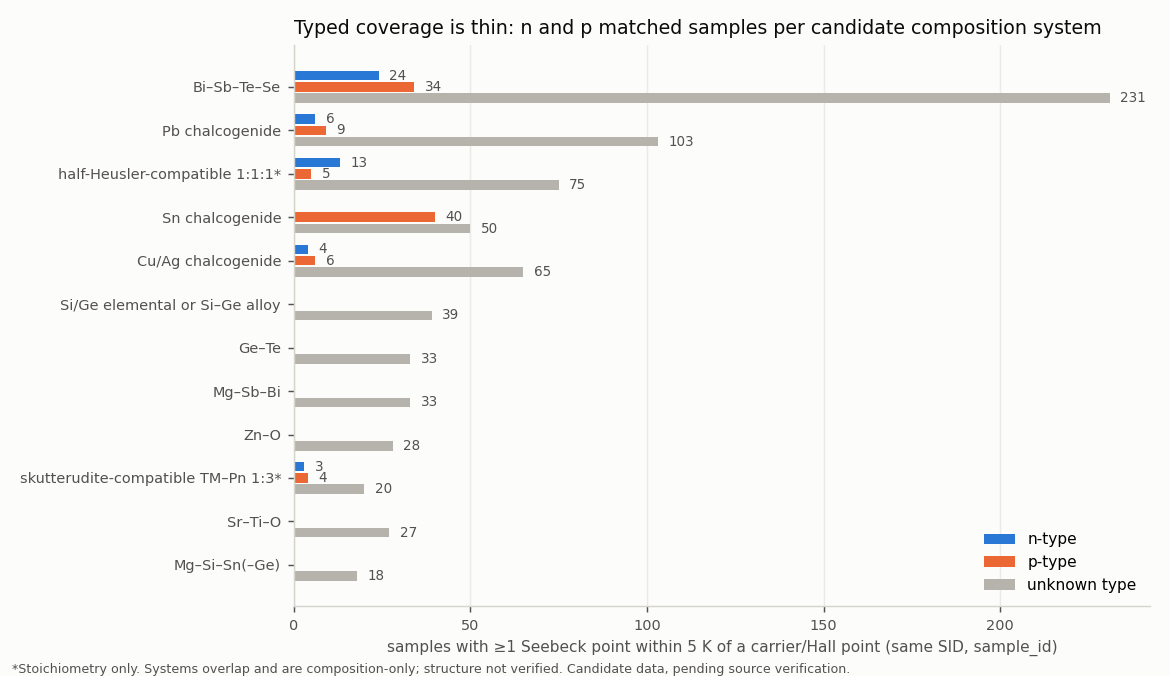

In [15]:
import matplotlib.pyplot as plt
cs = cov["systems"]; cs = cs[cs.carrier_type.isin(["n", "p", "unknown"])]
w = cs.pivot_table(index="systems", columns="carrier_type", values="matched_samples_tol5K", fill_value=0)
w = w.reindex(columns=["n", "p", "unknown"], fill_value=0)
w = w.loc[w.sum(1).sort_values().index]
short = {i: ("skutterudite-compatible TM–Pn 1:3*" if "skutterudite" in i else "half-Heusler-compatible 1:1:1*" if "Heusler" in i else i.split(" (")[0]) for i in w.index}
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=130)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
y = np.arange(len(w)); h = 0.26
colors = {"n": "#2a78d6", "p": "#eb6834", "unknown": "#b5b3ab"}
for k, off in zip(["n", "p", "unknown"], [h, 0, -h]):
    b = ax.barh(y + off, w[k], height=h - 0.04, color=colors[k], label={"n": "n-type", "p": "p-type", "unknown": "unknown type"}[k])
    for yi, v in zip(y + off, w[k]):
        if v: ax.text(v + 3, yi, f"{int(v)}", va="center", fontsize=7.5, color="#52514e")
ax.set_yticks(y, [short[i] for i in w.index], fontsize=8.5, color="#0b0b0b")
ax.set_xlabel("samples with ≥1 Seebeck point within 5 K of a carrier/Hall point (same SID, sample_id)", fontsize=8.5, color="#52514e")
ax.set_title("Typed coverage is thin: n and p matched samples per candidate composition system", fontsize=10.5, loc="left", color="#0b0b0b")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#d6d4cc"); ax.spines["bottom"].set_color("#d6d4cc"); ax.tick_params(colors="#52514e", labelsize=8)
ax.grid(axis="x", color="#ebeae4", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
fig.text(0.01, 0.005, "*Stoichiometry only. Systems overlap and are composition-only; structure not verified. Candidate data, pending source verification.", fontsize=7, color="#52514e")
plt.tight_layout(); plt.savefig("out/fig_np_matched_by_system.png", facecolor=fig.get_facecolor()); plt.show()

### 8.1 Screening criterion
A group is shortlisted when **both** n-type and p-type have at least **10 matched samples at 5 K from at least 3 distinct papers**. This threshold is a screening choice, and the next cell shows every group's numbers so the cut can be moved.

In [16]:
def shortlist(df, gcol, min_s=10, min_p=3):
    d = df[df.carrier_type.isin(["n", "p"])].pivot_table(index=gcol, columns="carrier_type",
         values=["matched_samples_tol5K", "matched_papers_tol5K", "matched_carrier_points_used_tol5K"], fill_value=0).astype(int)
    d.columns = [f"{a.replace('_tol5K','')}_{b}" for a, b in d.columns]
    for c in ["matched_samples_n","matched_samples_p","matched_papers_n","matched_papers_p"]:
        if c not in d: d[c] = 0
    allm = df[df.carrier_type == "ALL"].set_index(gcol)[["matched_samples_tol5K", "samples_S_and_carrier_or_hall_anywhere"]]
    d = d.join(allm.rename(columns={"matched_samples_tol5K": "matched_samples_all_types"}), how="right").fillna(0).astype(int)
    d["passes_both_n_and_p"] = (d.matched_samples_n >= min_s) & (d.matched_samples_p >= min_s) & (d.matched_papers_n >= min_p) & (d.matched_papers_p >= min_p)
    return d.sort_values(["passes_both_n_and_p", "matched_samples_all_types"], ascending=False)
sl_sys = shortlist(cov["systems"], "systems"); display(sl_sys)
sl_fam = shortlist(cov["family"], "family_label"); display(sl_fam.head(15))
sl_pg = shortlist(cov["primary"], "primary_group"); display(sl_pg.head(12))

,matched_carrier_points_used_n,matched_carrier_points_used_p,matched_papers_n,matched_papers_p,matched_samples_n,matched_samples_p,matched_samples_all_types,samples_S_and_carrier_or_hall_anywhere,passes_both_n_and_p
systems,,,,,,,,,
Bi–Sb–Te–Se,347,804,8,12,24,34,293,304,True
Pb chalcogenide (Pb–S/Se/Te),31,37,2,2,6,9,118,132,False
"A–B–C ≈1:1:1 (half-Heusler-compatible stoichiometry, structure NOT verified)",102,22,2,2,13,5,96,112,False
Sn chalcogenide (Sn–S/Se/Te),0,248,0,10,0,40,90,104,False
"Cu/Ag chalcogenide (Cu,Ag–S/Se/Te)",40,23,1,2,4,6,77,82,False
Si/Ge elemental or Si–Ge alloy,0,0,0,0,0,0,39,40,False
Ge–Te (GeTe-based),0,0,0,0,0,0,33,52,False
Mg–Sb–Bi,0,0,0,0,0,0,33,34,False
Zn–O (ZnO-based),0,0,0,0,0,0,28,32,False


,matched_carrier_points_used_n,matched_carrier_points_used_p,matched_papers_n,matched_papers_p,matched_samples_n,matched_samples_p,matched_samples_all_types,samples_S_and_carrier_or_hall_anywhere,passes_both_n_and_p
family_label,,,,,,,,,
<missing:empty>,309,1450,8,36,24,113,825,910,True
<missing:absent>,86,101,4,6,8,10,112,138,False
Bi2Te3,98,164,4,5,7,8,110,117,False
Antimonide,270,148,2,2,3,5,93,94,False
Selenide,0,55,0,4,0,8,78,86,False
Half-Heusler,90,22,2,2,12,5,73,82,False
Oxide,79,113,2,5,5,7,54,63,False
PbTe,0,69,0,1,0,1,51,52,False
Telluride,0,132,0,4,0,21,47,53,False


,matched_carrier_points_used_n,matched_carrier_points_used_p,matched_papers_n,matched_papers_p,matched_samples_n,matched_samples_p,matched_samples_all_types,samples_S_and_carrier_or_hall_anywhere,passes_both_n_and_p
primary_group,,,,,,,,,
telluride,254,1054,7,25,22,95,618,681,True
antimonide,52,406,1,12,3,39,250,270,False
selenide,34,234,1,9,3,22,229,256,False
oxide,151,418,3,13,9,23,170,183,False
elemental/metalloid alloy (no partner metal),270,225,2,5,3,18,118,123,False
stannide,141,127,3,4,14,8,103,114,False
mixed: selenide+telluride,104,51,1,1,4,1,47,50,False
sulfide,43,16,3,2,7,5,44,45,False
intermetallic/metallic (no anion-type major element),79,311,5,10,6,15,35,35,False


### 8.2 Recommendation (screening only, from the audited coverage above)
- **Bi–Sb–Te–Se** is the only candidate system that meets the n **and** p criterion: 24 n-type samples from 8 papers and 34 p-type samples from 12 papers at 5 K. Among original labels, *Bi2Te3* does not pass on typed data alone (7 n and 8 p samples). Among composition primary groups, *telluride* passes (22 n and 95 p samples). It is the recommended first candidate for a Seebeck–carrier study that needs both polarities. Its much larger untyped pool (231 matched samples) is the obvious next target for carrier-type recovery from the source papers.
- **Pb chalcogenides**, **half-Heusler-compatible 1:1:1** and **Cu/Ag chalcogenides** have matched data on both sides, but each side has only about 4–13 samples from 1–2 papers. They are **secondary candidates, conditional on manual carrier-type recovery** for their larger unknown pools (103, 75 and 65 matched samples).
- **Sn chalcogenides** are effectively **p-only** (40 p, 0 n). Any n-vs-p comparison there would be driven by paper selection.
- **Mg–Sb–Bi, Mg–Si–Sn, Ge–Te, Si/Ge, ZnO and SrTiO₃-based** have **no** matched samples with a documented carrier type. They are not recommended for n/p-resolved work until types are recovered from the sources. Note that no type was inferred from the known typical polarity of these materials; that would be guessing.
- The original-label view is dominated by `<missing:…>` labels (about 56% of matched samples). `<missing:empty>` passes the n/p criterion, but it is a pool of unlabelled records, not a family. This is why the composition-based view is needed alongside it.

Every count above is **candidate usable data**. Final eligibility requires checking the source paper for:
- the specimen identity (the same pellet for S and for Hall/n);
- the measurement method (Hall vs other carrier-density estimates, and the Hall factor assumption);
- the temperature;
- the provenance: “Experiment” label, or data reproduced from another paper.

## 9. Output files (in `out/`)
| file | content |
|---|---|
| `summary_ALL_by_carrier_type.csv` | overall coverage by carrier type |
| `summary_by_original_MaterialFamily.csv` | coverage by original label × carrier type |
| `summary_by_composition_primary_group_EXCLUSIVE.csv` | exclusive composition groups (rows can be summed) |
| `summary_by_composition_group_label_OVERLAPPING.csv` | overlapping labels (do not sum) |
| `summary_by_candidate_system_OVERLAPPING.csv` | candidate systems (overlapping) |
| `tolerance_sensitivity_*.csv` | 0/1/5/10 K sensitivity |
| `crosstab_MaterialFamily_vs_primary_group.csv`, `label_vs_composition_check_by_MaterialFamily.csv` | label audit |
| `candidate_matched_pairs_tol5K.csv`, `candidate_matched_pairs_tol10K.csv` | one row per Seebeck point × carrier quantity, with original values, T, ΔT, candidates, ambiguity and reuse |
| `direct_S_vs_carrier_curves_TEMPERATURE_NEEDS_SOURCE.csv` | Pisarenko-type curves |
| `sample_audit.csv` | every sample with label, parse status, groups, systems, type basis and flags |
| `curve_audit_target_properties.csv` | status of every Seebeck, carrier and Hall curve |
| `manual_review_records.csv`, `manual_review_counts.csv` | records needing manual review, by category |
| `run_manifest.json` | input hashes (checked against the upstream manifest), snapshot, settings, code hash, exclusions, review counts |

## References
1. Y. Katsura *et al.*, “Starrydata: from published plots to shared materials data”, *Sci. Technol. Adv. Mater.: Methods* **5**, 2506976 (2025). doi:10.1080/27660400.2025.2506976
2. Starrydata datasets documentation (official): https://github.com/starrydata/starrydata_datasets ; daily per-project release mirror used here: https://github.com/atsumitanaka/starrydata-datasets
3. G. J. Snyder, E. S. Toberer, “Complex thermoelectric materials”, *Nat. Mater.* **7**, 105 (2008). Background on the Seebeck–carrier-concentration (Pisarenko) relation and why it is temperature-specific.
4. N. W. Ashcroft, N. D. Mermin, *Solid State Physics* (1976), ch. 1 and 12. The Hall coefficient sign in the single-carrier picture and its breakdown with more than one carrier type.
